# LUMA - Loklany Urok Misrzostwa Artystycznego
 LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień; coraz więcej wystawcó, więcej gości (miejscowych i tuystów), okazjonalnie promocje i sezonowość

# Import bibliotek


In [37]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import chain
import pandas as pd

# Wygenerowanie synetetycznych danych

### Ustawienie ziarna RNG

In [5]:
RNG_SEED= 20261020
rng = np.random.default_rng(RNG_SEED)
print('Ustawiono ziarno RNG na :', RNG_SEED)

Ustawiono ziarno RNG na : 20261020


### Zdefiniowanie "stałych"

In [6]:
LUMA_FULL= 'Loklany Urok Mistrzostwa Artystycznego'
CATEGORIES=['Ceramika', 'Tekstylia', 'Biżuteria', 'Rękodzieło','Przetwory', 'Dekoracje', 'Stolarka', 'Masarstwo', 'Alkohole']


### Przygotowanie bazowych danych syntetycznych


"Katalog" kategorii i ich bazowe parametry generatywne (syntetyczne)

In [7]:
catalog = pd.DataFrame(
    {
    'category': CATEGORIES,
    "demand_loc_base": [120,180,130,80,160,150,70,90,110], #średni lokalny popyt (szt./tydz.)
    "demand_tur_base": [60,40,80,30,90,30,50,40,80], #średni popyt turystyczny (szt./tydz.)
    "price_pln_base": [8,120,150,230,40,35,250,215,135] #średna cena jednostkowa
})

### Wyliczony "typowy" przychód tygodniowy: (lokalni + turyści) *cena

In [8]:
catalog['revenue_avg_pln'] = (catalog['demand_loc_base'] + catalog['demand_tur_base']) * catalog['price_pln_base']


In [9]:
display(catalog)

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


### Przygotowanie funkcji pomocniczych do generowania danych tygodniowych


Generowanie poptu lokalnego i turystycznego na podstawie danych bazowych, z losowym szumem (multiplikatywnym) i opcjonalnymi boostami (%)


In [10]:
def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)

    return df[["category", "demand_loc", "demand_tur"]]

Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [11]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "demand_loc", "demand_tur", "revenue_loc", "revenue_tur", "revenue_pln"]]

Generowanie danych tygodniowych

In [12]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance=variance, boost_loc=boost_loc, boost_tur=boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

### Wygenerowanie danych tygodniowych

In [13]:
t1 = generate_weekly_data(catalog, rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per kategoria (PLN)")
display(t1)
print("Łączny przychód w tygodniu 1 (PLN): ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per kategoria (PLN)


,category,demand_loc,demand_tur,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,86,49,688,392,1080,8
1,Tekstylia,177,28,21240,3360,24600,120
2,Biżuteria,89,78,13350,11700,25050,150
3,Rękodzieło,98,28,22540,6440,28980,230
4,Przetwory,193,92,7720,3680,11400,40
5,Dekoracje,140,32,4900,1120,6020,35
6,Stolarka,76,57,19000,14250,33250,250
7,Masarstwo,85,41,18275,8815,27090,215
8,Alkohole,138,76,18630,10260,28890,135


Łączny przychód w tygodniu 1 (PLN):  186360


### Analiza i wizualizacja danych

Podstawowe wykresy

<Axes: >

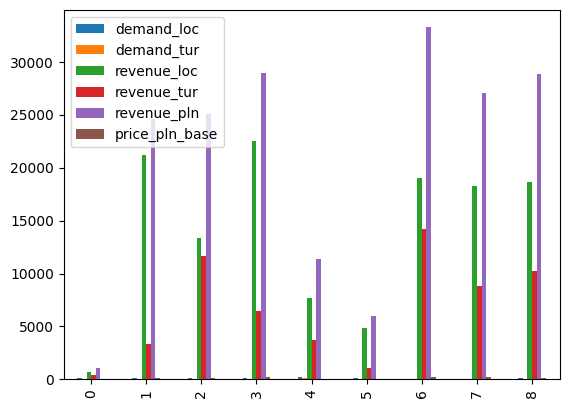

In [14]:
t1.plot.bar()

<Axes: >

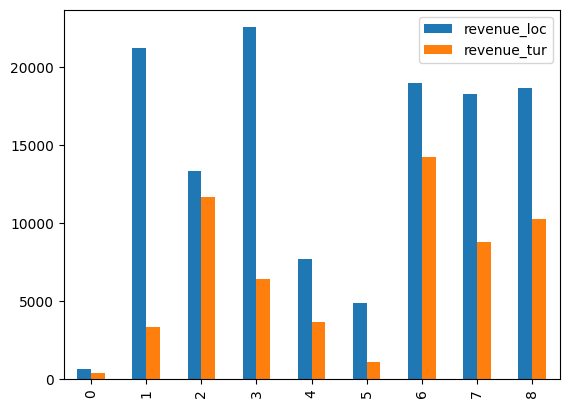

In [15]:
t1[["revenue_loc", "revenue_tur"]].plot.bar()

<Axes: >

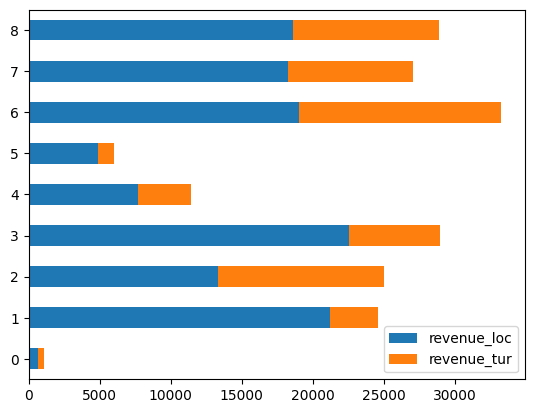

In [16]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

Minimalny wykres

<BarContainer object of 9 artists>

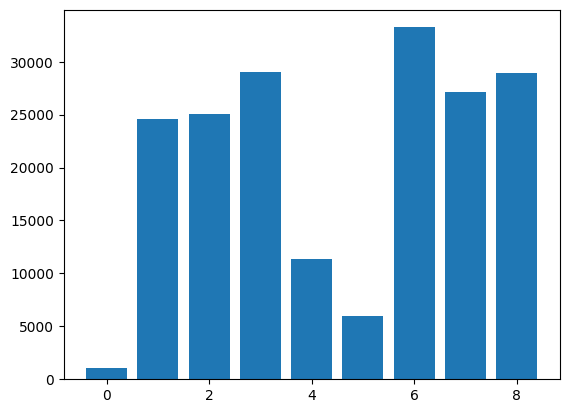

In [17]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

Jawne tworzenie i wyświetlanie wykresu

In [18]:
heights = t1["revenue_pln"]
categories = t1["category"]

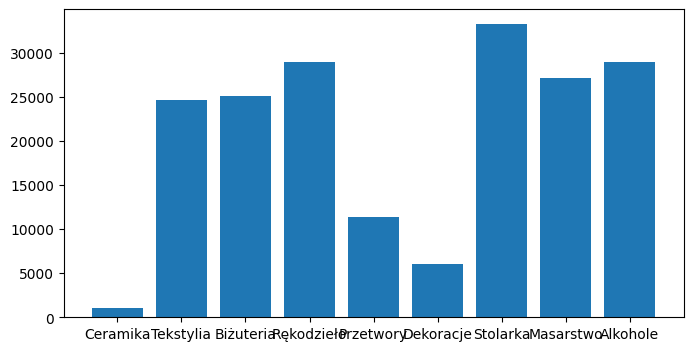

In [19]:
plt.figure(figsize=(8,4))
plt.bar(categories, heights)
plt.show()

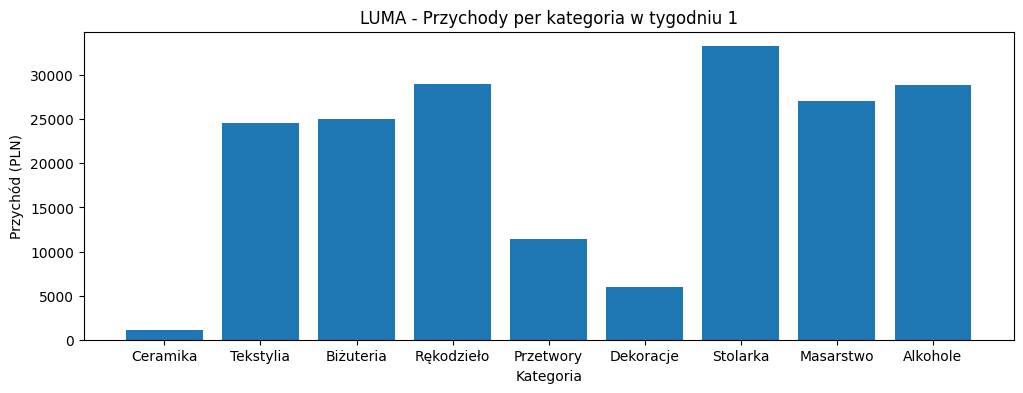

In [20]:
plt.figure(figsize=(12,4))
plt.bar(categories, heights)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()

Etykiety wartości i formatowanie liczb

In [21]:
def format_pln(x: float):
    return f"{int(round(x)):,}PLN".replace(",", "\u202f")

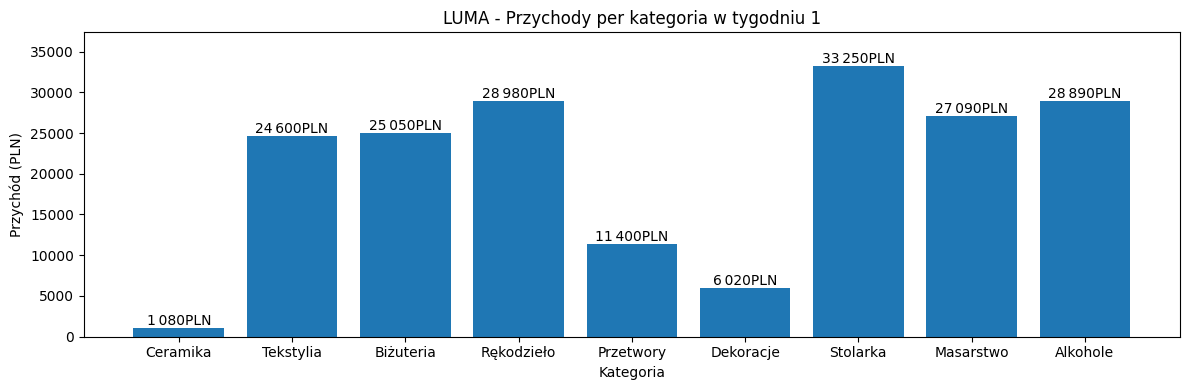

In [22]:
plt.figure(figsize=(12,4))
bars = plt.bar(categories, heights)
ymin, ymax = plt.ylim()
pad = (ymax - ymin) * 0.07
plt.ylim(ymin, ymax + pad)
for bar in bars:
    x = bar.get_x() + bar.get_width() / 2
    y = bar.get_height()
    plt.text(x, y, format_pln(y), ha='center', va='bottom')
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

In [23]:
def pad_axis(factor=0.07):
    ymin, ymax = plt.ylim() #pobranie wartości min i max dla y
    pad = (ymax - ymin) * factor
    plt.ylim(ymin, ymax +pad) #ustawienie nowej wartosci maxy

In [24]:
def label_bars_pln(bars):
    for bar in bars:
        x = bar.get_x() + bar.get_width()/2
        y= bar.get_height()
        plt.text(x,y, format_pln(y), ha="center", va="bottom")

Formatowanie etykiet podziałki osi

In [25]:
def format_tys(x: float, decimals: int = 0) -> str:
    v = x / 1000.0
    if decimals == 0:
        s = f"{int(round(v)):,}".replace(",","\u202f")
    else:
        s = f"{v:,.{decimals}f}".replace(",","\u202f").replace(".", ",")
    return s + " tys."

In [26]:
def format_mln(x: float, decimals: int = 0) -> str:
    v = x / 1000000.0
    if decimals == 0:
        s = f"{int(round(v)):,}".replace(",","\u202f")
    else:
        s = f"{v:,.{decimals}f}".replace(",","\u202f").replace(".", ",")
    return s + " mln."

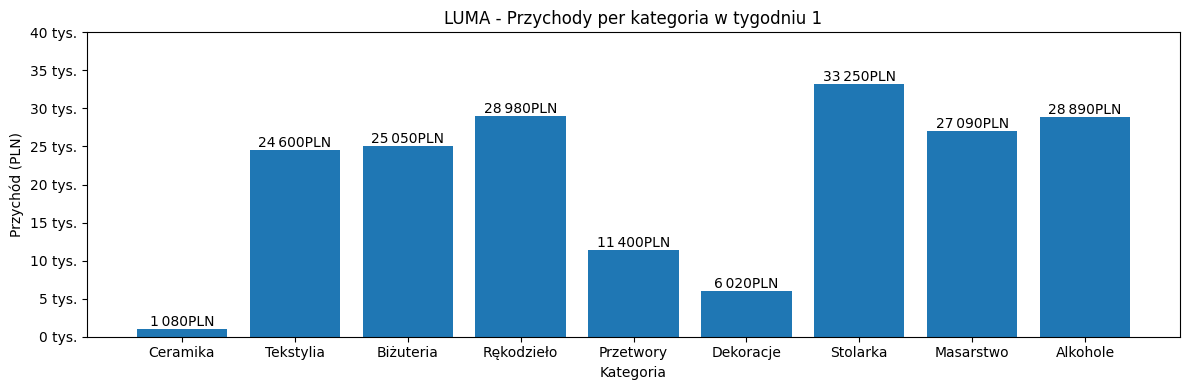

In [27]:
plt.figure(figsize=(12,4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
ypos, ylab_old = plt.yticks()
ylab_new = [format_tys(y) for y in ypos]
plt.yticks(ypos, ylab_new)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

In [28]:
def format_ytics_type():
    ypos, _ = plt.yticks()
    ylab_new = [format_tys(y) for y in ypos]
    plt.yticks(ypos, ylab_new)
    

Sortowanie kategorii dla łatwiejszego porównania

In [29]:
t1_sorted = t1.sort_values(by="revenue_pln", ascending=False).reset_index()
categories = t1_sorted["category"]
heights = t1_sorted["revenue_pln"]

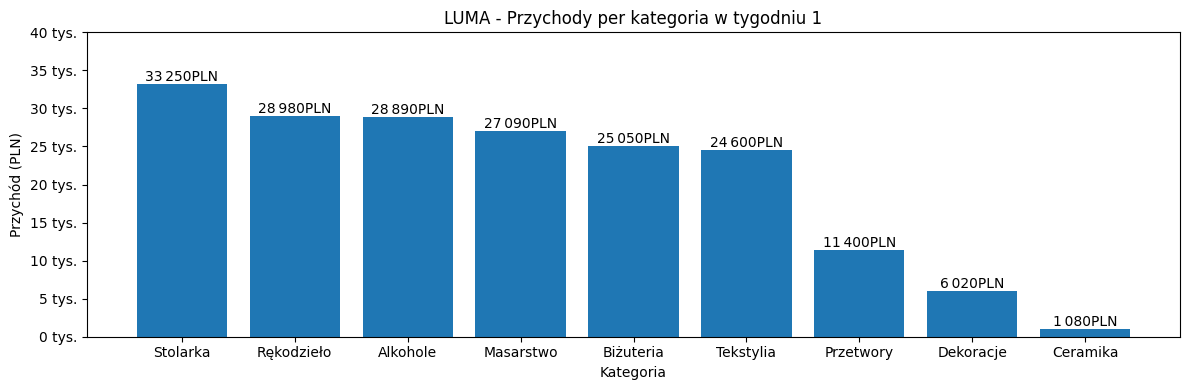

In [30]:
plt.figure(figsize=(12,4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
format_ytics_type()
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

Siatka w tle wykresu

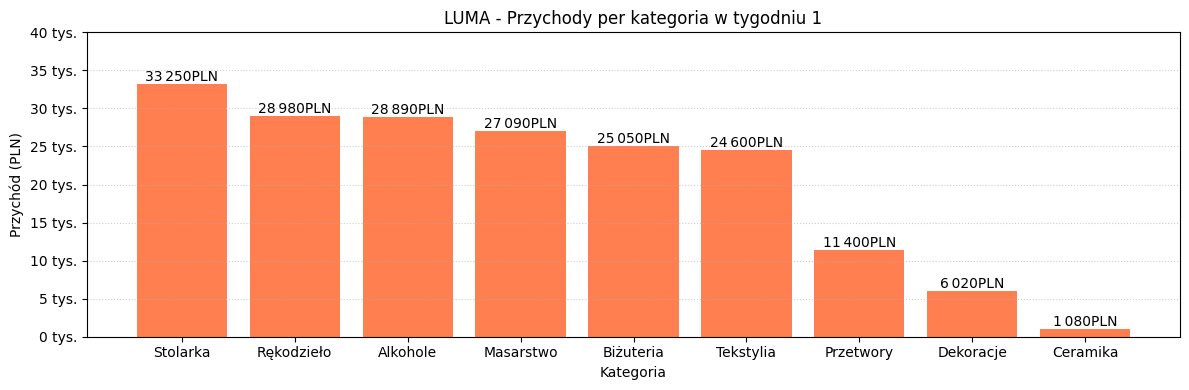

In [31]:
plt.figure(figsize=(12,4))
bars = plt.bar(categories, heights, color="coral")
pad_axis()
label_bars_pln(bars)
format_ytics_type()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

Siatka w tle wykresu

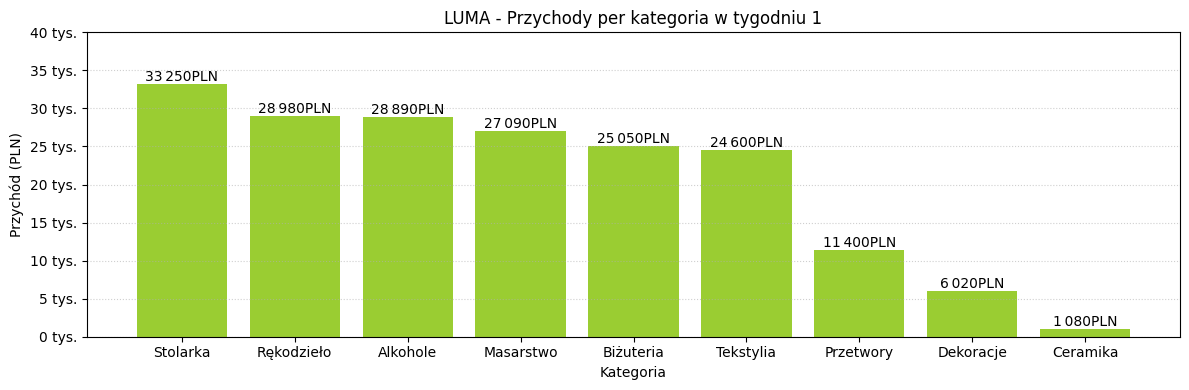

In [32]:
plt.figure(figsize=(12,4))
bars = plt.bar(categories, heights, color="yellowgreen")
pad_axis()
label_bars_pln(bars)
format_ytics_type()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.title("LUMA - Przychody per kategoria w tygodniu 1")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

## Analiza i wizualizacja danych - 2 serie danych

### Wygenerowanie danych tygodniowych dla Tygodnia 2

Mini-festiwal przyciąga klientów: lokalni + 13%, turyści + 20%

In [33]:
boost_loc = 0.13
boost_tur = 0.20

t2 = generate_weekly_data(catalog, rng, boost_loc=boost_loc, boost_tur=boost_tur)
t2 = t2.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 2 - przychody per kategoria (PLN)")
display(t2)
print("Łączny przychód w tygodniu 1 (PLN): ", format_pln(t1["revenue_pln"].sum()))
print("Łączny przychód w tygodniu 2 (PLN): ", format_pln(t2["revenue_pln"].sum()))

Tydzień 2 - przychody per kategoria (PLN)


,category,demand_loc,demand_tur,revenue_loc,revenue_tur,revenue_pln,price_pln_base
0,Ceramika,145,90,1160,720,1880,8
1,Tekstylia,231,41,27720,4920,32640,120
2,Biżuteria,100,88,15000,13200,28200,150
3,Rękodzieło,67,33,15410,7590,23000,230
4,Przetwory,161,135,6440,5400,11840,40
5,Dekoracje,174,33,6090,1155,7245,35
6,Stolarka,82,72,20500,18000,38500,250
7,Masarstwo,97,42,20855,9030,29885,215
8,Alkohole,125,144,16875,19440,36315,135


Łączny przychód w tygodniu 1 (PLN):  186 360PLN
Łączny przychód w tygodniu 2 (PLN):  209 505PLN


### Przygotowanie danych do wykresu

In [34]:
categories = t1_sorted["category"]
t1_revenue_total = t1_sorted["revenue_pln"]
t2_revenue_total = t2.set_index("category").loc[categories]["revenue_pln"]
x_locs = np.arange(len(categories))
bar_width = 0.4
bar_half = bar_width / 2

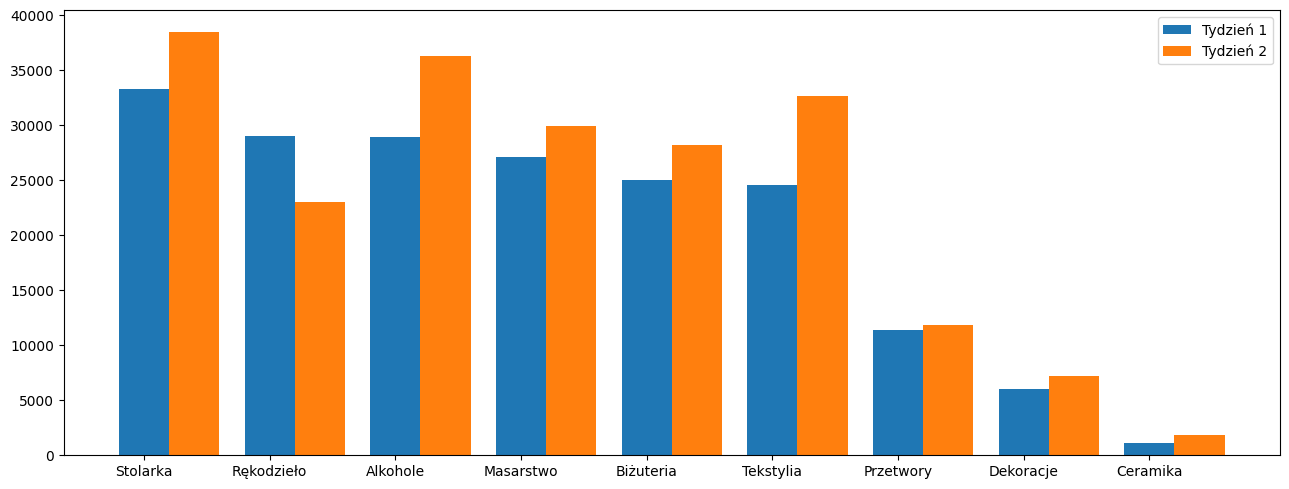

In [35]:
plt.figure(figsize=(13, 5))
plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1", tick_label=categories)
plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2")
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'format_ytics_tys' is not defined

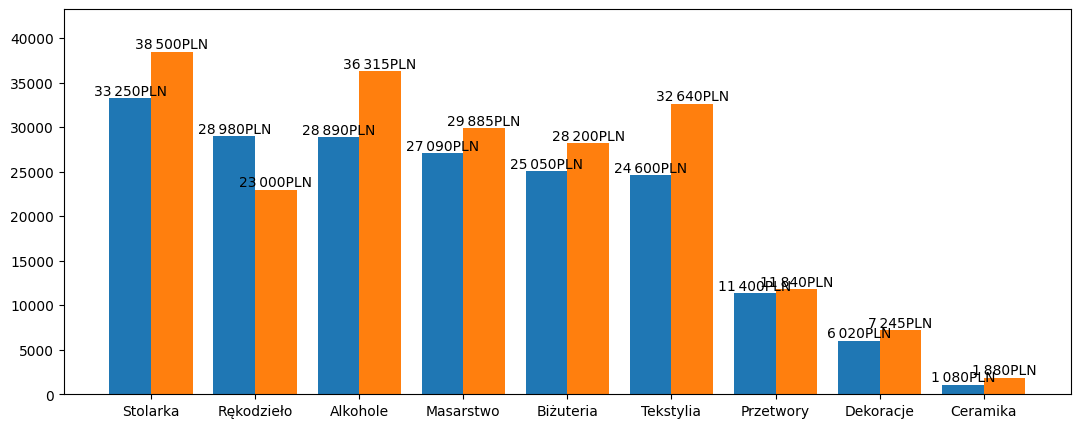

In [38]:
plt.figure(figsize=(13, 5))
bar_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1")
bar_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2")
plt.xticks(x_locs, categories)
pad_axis()
label_bars_pln(chain(bar_1, bar_2))
format_ytics_tys()
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

def format_sep(x:float) -> str:
    return f"{int(round(x)):,}".replace(",", "\u202f")

In [ ]:
plt.figure(figsize=(13, 5))
bars_1 = plt.bar(x_locs-bar_half, t1_revenue_total, width=bar_width, label="Tydzień 1", color="plum")
bars_2 = plt.bar(x_locs+bar_half, t2_revenue_total, width=bar_width, label="Tydzień 2", color="khaki")
plt.xticks(x_locs, categories)
pad_axis()
for b in bars_1:
    x,y = b.get_x(), b.get_height()
    plt.text(x, y, format_sep(y), ha="left", va="bottom")

for b in bars_2:
    x,y = b.get_x()+ b.get_width(), b.get_height()
    plt.text(x, y, format_sep(y), ha="right", va="bottom")

format_ytics_tys()
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.title("LUMA - Porównanie przychodów per kategoria w tygodniu 1 i 2")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.legend()
plt.tight_layout()
plt. show()